In [2]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

In [9]:
####################################################
# INPUTS
####################################################
pm10 = ctrl.Antecedent(np.arange(0, 301, 1), "pm10")
pm25 = ctrl.Antecedent(np.arange(0, 161, 1), "pm25")
wind = ctrl.Antecedent(np.arange(0, 41, 1), "wind")

####################################################
# OUTPUT
####################################################
risk = ctrl.Consequent(np.arange(0, 10.1, 0.1), "environmental_risk")

####################################################
# PM10
####################################################
pm10["good"] = fuzz.zmf(pm10.universe, 10, 20)
pm10["fair"] = fuzz.pimf(pm10.universe, 10, 20, 38, 52)
pm10["moderate"] = fuzz.pimf(pm10.universe, 38, 52, 105, 135)
pm10["poor"] = fuzz.pimf(pm10.universe, 105, 135, 180, 210)
pm10["very_poor"] = fuzz.smf(pm10.universe, 180, 210)

####################################################
# PM25
####################################################
pm25["good"] = fuzz.zmf(pm25.universe, 3, 7)
pm25["fair"] = fuzz.pimf(pm25.universe, 3, 7, 12, 18)
pm25["moderate"] = fuzz.pimf(pm25.universe, 12, 18, 44, 56)
pm25["poor"] = fuzz.pimf(pm25.universe, 44, 56, 82, 98)
pm25["very_poor"] = fuzz.smf(pm25.universe, 82, 98)

####################################################
# WIND
####################################################
wind["low"] = fuzz.trapmf(wind.universe, [0, 0, 6, 12])
wind["medium"] = fuzz.trimf(wind.universe, [8, 18, 28])
wind["high"] = fuzz.trapmf(wind.universe, [22, 30, 40, 40])

####################################################
# OUTPUT
####################################################
risk["very_low"]  = fuzz.trapmf(risk.universe, [0, 0, 1, 2.5])
risk["low"] = fuzz.trimf(risk.universe, [1, 2.5, 4.5])
risk["medium"] = fuzz.trimf(risk.universe, [3.5, 5, 6.5])
risk["high"] = fuzz.trimf(risk.universe, [5.5, 7.5, 9])
risk["very_high"] = fuzz.trapmf(risk.universe, [7.5, 9, 10, 10])
####################################################
# RULES
####################################################
# Orden de severidad de las etiquetas de contaminación
NIVELES_PM = ["good", "fair", "moderate", "poor", "very_poor"]
 
# Nivel de riesgo correspondiente a cada índice de severidad
NIVELES_RIESGO = ["very_low", "low", "medium", "high", "very_high"]
 
# Ajuste que introduce el viento sobre el nivel base
AJUSTE_VIENTO = {
    "low":     +1, # calma: menor dispersión, se agrava el nivel
    "medium":   0, # condiciones neutras
    "high":    -1, # viento intenso: mayor dispersión, se relaja
}
 
 
def _nivel_resultante(idx_pm10, idx_pm25, etiqueta_viento):
    """Determina la etiqueta de salida para una combinación de entradas.
 
    El nivel base lo fija el peor de los dos contaminantes, siguiendo el
    criterio del índice europeo de calidad del aire. El viento lo ajusta
    en un escalón, acotado al rango disponible.
    """
    base = max(idx_pm10, idx_pm25)
    ajustado = base + AJUSTE_VIENTO[etiqueta_viento]
    ajustado = max(0, min(len(NIVELES_RIESGO) - 1, ajustado))
    return NIVELES_RIESGO[ajustado]
 
 
def _construir_reglas():
    reglas = []
    for i, et_pm10 in enumerate(NIVELES_PM):
        for j, et_pm25 in enumerate(NIVELES_PM):
            for et_wind in AJUSTE_VIENTO:
                salida = _nivel_resultante(i, j, et_wind)
                reglas.append(
                    ctrl.Rule(
                        pm10[et_pm10] & pm25[et_pm25] & wind[et_wind],
                        risk[salida],
                    )
                )
    return reglas
 
 
rules = _construir_reglas()
 
 
####################################################
# CONTROL SYSTEM
####################################################
fis = ctrl.ControlSystem(rules)
simulation = ctrl.ControlSystemSimulation(fis)

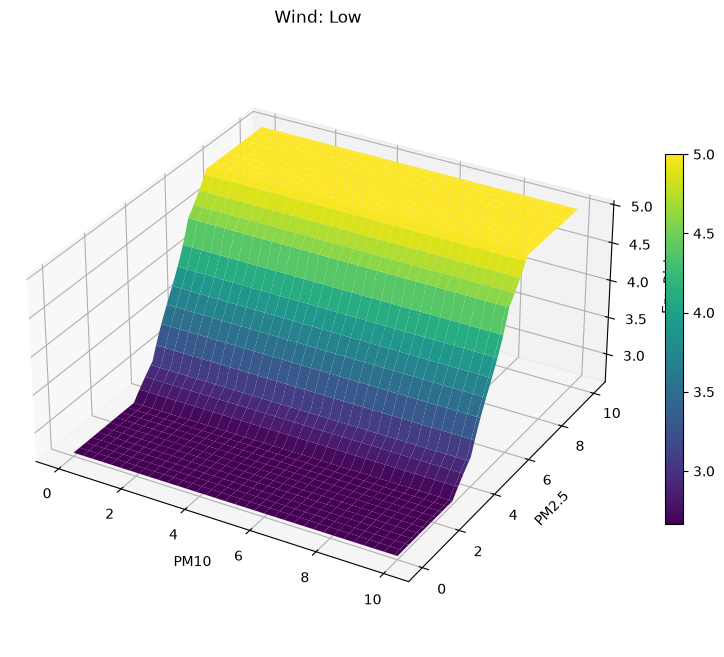

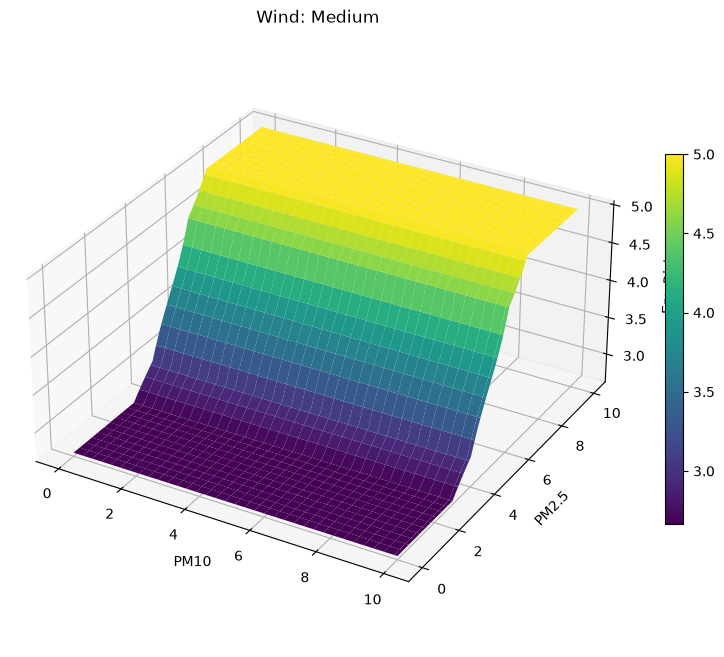

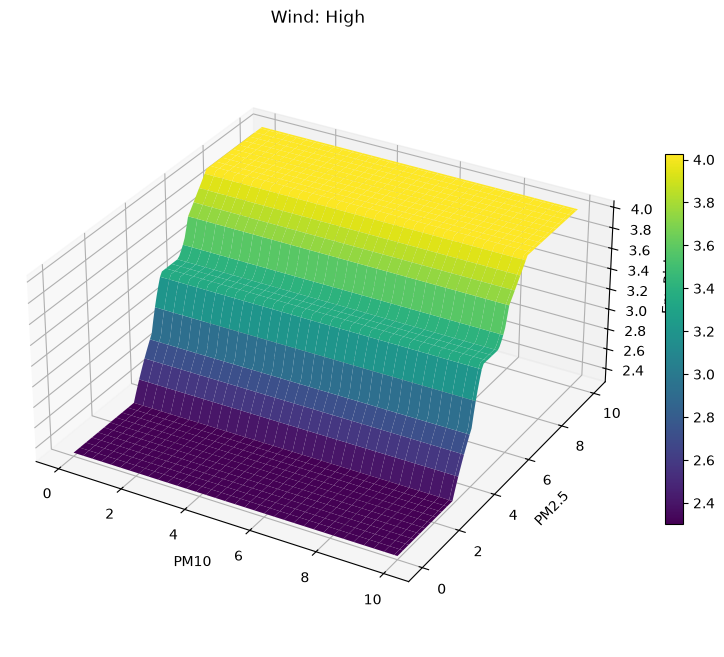

In [8]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def plot_surface(wind_inp, title):

    pm10_range = np.linspace(0, 10, 101)
    pm25_range = np.linspace(0, 10, 101)

    PM10, PM25 = np.meshgrid(pm10_range, pm25_range)

    OUTPUT = np.zeros_like(PM10)

    for i in range(PM10.shape[0]):
        for j in range(PM10.shape[1]):

            sim = ctrl.ControlSystemSimulation(fis)

            sim.input["pm10"] = PM10[i, j]
            sim.input["pm25"] = PM25[i, j]
            sim.input["wind"] = wind_inp

            sim.compute()

            OUTPUT[i, j] = sim.output["environmental_risk"]

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")

    surface = ax.plot_surface(
        PM10,
        PM25,
        OUTPUT,
        cmap="viridis",
        edgecolor="none",
        antialiased=True
    )

    ax.set_xlabel("PM10")
    ax.set_ylabel("PM2.5")
    ax.set_zlabel("Env Risk")
    ax.set_title(title)
    ax.set_box_aspect((1,1,0.5))

    fig.colorbar(surface, shrink=0.6)

    plt.show()

plot_surface(0, "Wind: Low")
plot_surface(5, "Wind: Medium")
plot_surface(10, "Wind: High")